In [1]:
import pandas as pd

data = {
    "OrderID": [1001, 1002, 1003, 1004, 1005, 1006,
                1007, 1008, 1009, 1010, 1011, 1012],

    "Date": [
        "2026-01-05", "2026-01-12", "2026-01-18",
        "2026-02-03", "2026-02-14", "2026-02-21",
        "2026-03-04", "2026-03-15", "2026-03-25",
        "2026-04-02", "2026-04-11", "2026-04-23"
    ],

    "Region": [
        "North", "South", "East", "North",
        "South", "East", "North", "South",
        "East", "North", "South", "East"
    ],

    "Product": [
        "Laptop", "Mouse", "Laptop", "Mouse",
        "Keyboard", "Laptop", "Keyboard", "Laptop",
        "Mouse", "Laptop", "Mouse", "Keyboard"
    ],

    "Units": [1, 4, 1, 5, 2, 1, 3, 1, 6, 1, 3, 2],

    "UnitPrice": [
        1000, 25, 1000, 25, 75, 1000,
        75, 1000, 25, 1000, 25, 75
    ],

    "DiscountPct": [
        0.05, 0.00, 0.10, 0.10, 0.00, 0.05,
        0.00, 0.15, 0.00, 0.10, 0.00, 0.05
    ],

    "Channel": [
        "Online", "Store", "Store", "Online",
        "Store", "Online", "Store", "Online",
        "Store", "Online", "Online", "Store"
    ]
}

df = pd.DataFrame(data)

In [3]:
df

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Channel
0,1001,2026-01-05,North,Laptop,1,1000,0.05,Online
1,1002,2026-01-12,South,Mouse,4,25,0.00,Store
2,1003,2026-01-18,East,Laptop,1,1000,0.10,Store
3,1004,2026-02-03,North,Mouse,5,25,0.10,Online
4,1005,2026-02-14,South,Keyboard,2,75,0.00,Store
5,1006,2026-02-21,East,Laptop,1,1000,0.05,Online
6,1007,2026-03-04,North,Keyboard,3,75,0.00,Store
7,1008,2026-03-15,South,Laptop,1,1000,0.15,Online
8,1009,2026-03-25,East,Mouse,6,25,0.00,Store
9,1010,2026-04-02,North,Laptop,1,1000,0.10,Online


In [4]:
df["OrderID"].nunique(), len(df)

(12, 12)

In [5]:
import numpy as np
import matplotlib.pyplot as plt

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["Date"].isna().sum()
df.dtypes

Matplotlib is building the font cache; this may take a moment.


OrderID                 int64
Date           datetime64[us]
Region                    str
Product                   str
Units                   int64
UnitPrice               int64
DiscountPct           float64
Channel                   str
dtype: object

In [6]:
df["Revenue"] = (
    df["Units"]
    * df["UnitPrice"]
    * (1 - df["DiscountPct"])
)

df

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Channel,Revenue
0,1001,2026-01-05,North,Laptop,1,1000,0.05,Online,950.0
1,1002,2026-01-12,South,Mouse,4,25,0.00,Store,100.0
2,1003,2026-01-18,East,Laptop,1,1000,0.10,Store,900.0
3,1004,2026-02-03,North,Mouse,5,25,0.10,Online,112.5
4,1005,2026-02-14,South,Keyboard,2,75,0.00,Store,150.0
5,1006,2026-02-21,East,Laptop,1,1000,0.05,Online,950.0
6,1007,2026-03-04,North,Keyboard,3,75,0.00,Store,225.0
7,1008,2026-03-15,South,Laptop,1,1000,0.15,Online,850.0
8,1009,2026-03-25,East,Mouse,6,25,0.00,Store,150.0
9,1010,2026-04-02,North,Laptop,1,1000,0.10,Online,900.0


In [7]:
highest_revenue_orders = (
    df.sort_values("Revenue", ascending=False)
    [
        [
            "OrderID",
            "Date",
            "Region",
            "Product",
            "Units",
            "UnitPrice",
            "DiscountPct",
            "Revenue"
        ]
    ]
    .head(5)
)

highest_revenue_orders

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Revenue
0,1001,2026-01-05,North,Laptop,1,1000,0.05,950.0
5,1006,2026-02-21,East,Laptop,1,1000,0.05,950.0
9,1010,2026-04-02,North,Laptop,1,1000,0.10,900.0
2,1003,2026-01-18,East,Laptop,1,1000,0.10,900.0
7,1008,2026-03-15,South,Laptop,1,1000,0.15,850.0


In [8]:
region_summary = (
    df.groupby("Region")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        Orders=("OrderID", "count"),
        AverageRevenuePerOrder=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

region_summary

,TotalRevenue,Orders,AverageRevenuePerOrder
Region,,,
North,2187.5,4,546.875
East,2142.5,4,535.625
South,1175.0,4,293.750


In [9]:
product_summary = (
    df.groupby("Product")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Units", "sum"),
        Orders=("OrderID", "count")
    )
    .sort_values("TotalRevenue", ascending=False)
)

product_summary

,TotalRevenue,UnitsSold,Orders
Product,,,
Laptop,4550.0,5,5
Keyboard,517.5,7,3
Mouse,437.5,18,4


In [10]:
df["Month"] = df["Date"].dt.to_period("M").astype(str)

monthly_summary = (
    df.groupby("Month")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        Orders=("OrderID", "count")
    )
    .sort_index()
)

monthly_summary

,TotalRevenue,Orders
Month,,
2026-01,1950.0,3
2026-02,1212.5,3
2026-03,1225.0,3
2026-04,1117.5,3


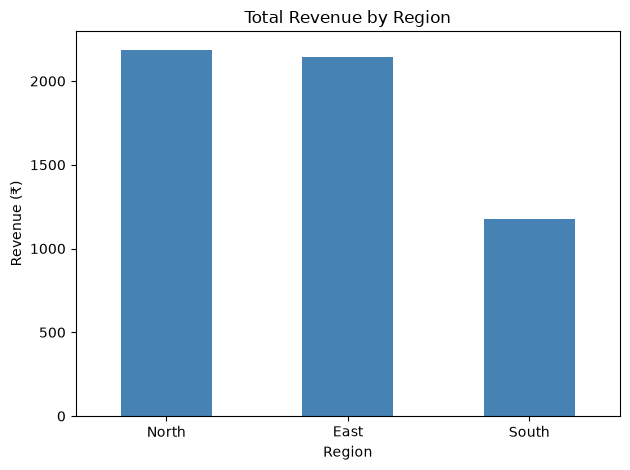

In [11]:
region_summary["TotalRevenue"].plot(
    kind="bar",
    color="steelblue",
    title="Total Revenue by Region"
)

plt.xlabel("Region")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

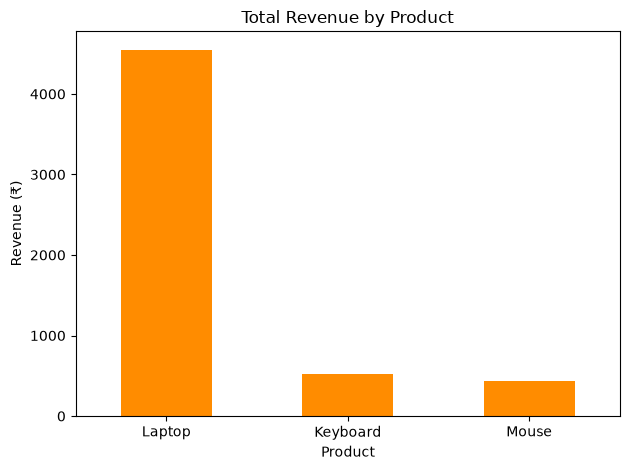

In [12]:
product_summary["TotalRevenue"].plot(
    kind="bar",
    color="darkorange",
    title="Total Revenue by Product"
)

plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()